RESULTADOS DE LA SIMULACION
Absorcion promedio: 0.745
Porcentaje con absorcion >= 0.7: 67.3 %


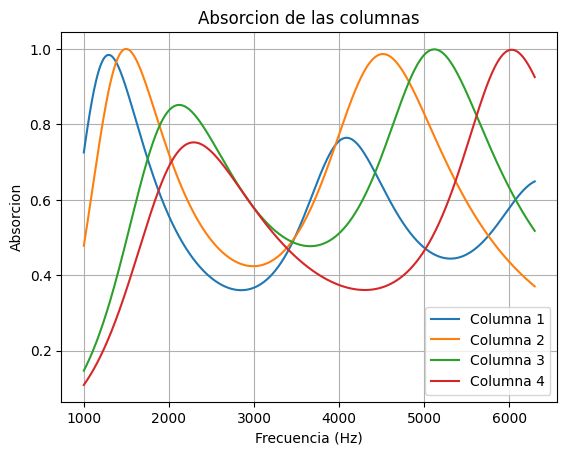

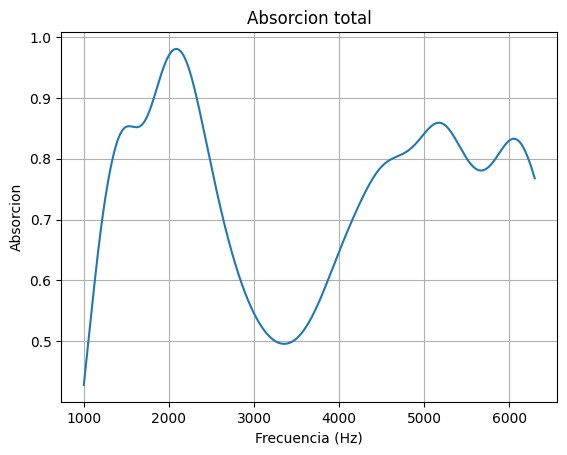

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Datos del aire
rho0 = 1.205
c0 = 343
eta = 1.81e-5
A1 = 6.65

# Frecuencias
freqs = np.linspace(1000, 6300, 5301)
t = 1.0

# Datos de las columnas
diametros = [0.5, 0.6, 0.9, 1.0]
cavidades = [[4, 6, 8], [6, 2, 10], [8, 4, 6], [8, 8, 2]]
colores = ["gold", "teal", "orchid", "slateblue"]

# Guardar resultados
alphas = []
Z_columnas = []

# Calcular cada columna
for n in range(4):

    d = diametros[n]
    omega = 2 * np.pi * freqs
    k0 = omega / c0

    # Pasar medidas a metros
    dm = d * 1e-3
    tm = t * 1e-3

    # Porosidad
    sigma = np.pi * (d / 2)**2 / A1

    # Impedancia del poro
    k = dm * np.sqrt(rho0 * omega / (4 * eta))
    Rs = 0.5 * np.sqrt(2 * eta * rho0 * omega)
    epsilon = 6 - 26 * d + 40 * d**2
    delta = (0.8 * d + 0.45) * (d / t)

    real = (32 * eta * tm / (dm**2 * sigma)) * (np.sqrt(1 + k**2 / 32) + 2 * epsilon * Rs)
    imag = (omega * rho0 * tm / sigma) * (1 + (9 + k**2 / 2)**(-0.5) + delta * (dm / tm))

    Zp = real + 1j * imag

    # Matriz inicial
    TT = np.zeros((len(freqs), 2, 2), dtype=complex)

    for i in range(len(freqs)):
        TT[i] = np.eye(2)

    # Calcular las cavidades
    for Dmm in cavidades[n]:

        D = Dmm * 1e-3

        for i in range(len(freqs)):

            Tp = np.array([[1, Zp[i]], [0, 1]], dtype=complex)

            arg = k0[i] * D

            Tc = np.array([
                [np.cos(arg), 1j * rho0 * c0 * np.sin(arg)],
                [1j * np.sin(arg) / (rho0 * c0), np.cos(arg)]
            ])

            TT[i] = TT[i] @ Tp @ Tc

    # Impedancia total de la columna
    ZT = (TT[:, 0, 0] / TT[:, 1, 0]) / (rho0 * c0)
    Z_columnas.append(ZT)

    # Coeficiente de absorción
    alpha = 4 * np.real(ZT) / ((1 + np.real(ZT))**2 + np.imag(ZT)**2)
    alphas.append(alpha)

# Combinar las cuatro columnas
suma = np.zeros(len(freqs), dtype=complex)

for ZT in Z_columnas:
    suma = suma + 1 / ZT

Z_total = 4 / suma

# Absorción total
alpha_total = 4 * np.real(Z_total) / ((1 + np.real(Z_total))**2 + np.imag(Z_total)**2)

# Resultados
promedio = np.mean(alpha_total)
porcentaje = np.sum(alpha_total >= 0.7) / len(alpha_total) * 100

print("========================================")
print("RESULTADOS DE LA SIMULACION")
print("Absorcion promedio:", round(promedio, 3))
print("Porcentaje con absorcion >= 0.7:", round(porcentaje, 1), "%")
print("========================================")

# Graficas
plt.plot(freqs, alphas[0], label="Columna 1") 
plt.plot(freqs, alphas[1], label="Columna 2") 
plt.plot(freqs, alphas[2], label="Columna 3") 
plt.plot(freqs, alphas[3], label="Columna 4") 
plt.xlabel("Frecuencia (Hz)") 
plt.ylabel("Absorcion") 
plt.title("Absorcion de las columnas") 
plt.legend() 
plt.grid() 
plt.show() 
plt.plot(freqs, alpha_total) 
plt.xlabel("Frecuencia (Hz)") 
plt.ylabel("Absorcion") 
plt.title("Absorcion total") 
plt.grid() 
plt.show()
